# Dry Bean Variety Classification

This project compares four machine learning classifiers for identifying **seven dry bean varieties** from measurable seed characteristics. The dataset contains **13,611 samples** and **16 numeric shape and size features**, sourced from the UCI Machine Learning Repository.

**Models:** k-Nearest Neighbors (k-NN), Gaussian Naive Bayes, Decision Tree, and Support Vector Machine (SVM).

**Evaluation:** Accuracy, macro-averaged precision, recall, F1-score, classification reports, and confusion matrices.

## 1. Environment Setup

Install `ucimlrepo` for downloading the dataset. `openpyxl` supports an Excel-file fallback.

In [ ]:
# Install required packages
!pip -q install ucimlrepo openpyxl

## 2. Libraries

Pandas and NumPy handle tabular data, Matplotlib displays evaluation plots, and scikit-learn provides preprocessing pipelines, classification models, and evaluation metrics.

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

plt.rcParams["figure.figsize"] = (8, 6)

## 3. Dataset Loading

The notebook first requests UCI Dry Bean dataset **ID 602** using `ucimlrepo`. If this is unavailable, the loader attempts a local Excel or CSV copy. The predictors are stored in `X`, and bean varieties are stored in `y`.

In [ ]:
def load_dry_bean_dataset():
    # Primary source: UCI repository via ucimlrepo
    try:
        dry_bean = fetch_ucirepo(id=602)
        X = dry_bean.data.features.copy()
        y = dry_bean.data.targets.copy()

        # Ensure target is a pandas Series
        if isinstance(y, pd.DataFrame):
            y = y.iloc[:, 0]
        else:
            y = pd.Series(y)

        source = "Repositori UCI melalui ucimlrepo"
        metadata = dry_bean.metadata
        variables = dry_bean.variables
        return X, y, source, metadata, variables
    except Exception as e:
        print("Pengambilan data online gagal:", e)
        print("Mencoba fallback lokal...")

    # Fallback 1: Excel file
    try:
        df = pd.read_excel("Dry_Bean_Dataset.xlsx")
        target_col = "Class" if "Class" in df.columns else df.columns[-1]
        X = df.drop(columns=[target_col]).copy()
        y = df[target_col].copy()
        source = "File Excel lokal: Dry_Bean_Dataset.xlsx"
        metadata, variables = None, None
        return X, y, source, metadata, variables
    except Exception as e:
        print("Fallback Excel gagal:", e)

    # Fallback 2: ARFF file
    try:
        from scipy.io import arff
        data, meta = arff.loadarff("Dry_Bean_Dataset.arff")
        df = pd.DataFrame(data)

        # Decode byte strings if needed
        for col in df.columns:
            if df[col].dtype == object:
                df[col] = df[col].apply(lambda x: x.decode("utf-8") if isinstance(x, bytes) else x)

        target_col = "Class" if "Class" in df.columns else df.columns[-1]
        X = df.drop(columns=[target_col]).copy()
        y = df[target_col].copy()
        source = "File ARFF lokal: Dry_Bean_Dataset.arff"
        metadata, variables = None, None
        return X, y, source, metadata, variables
    except Exception as e:
        print("Fallback ARFF gagal:", e)

    raise FileNotFoundError(
        "Dataset tidak dapat dimuat. Pastikan koneksi internet tersedia "
        "atau unggah Dry_Bean_Dataset.xlsx / Dry_Bean_Dataset.arff ke sesi Colab."
    )

X, y, data_source, metadata, variables = load_dry_bean_dataset()

print("Sumber data:", data_source)
print("Ukuran feature matrix:", X.shape)
print("Ukuran target:", y.shape)

display(X.head())
display(y.head())

Sumber data: Repositori UCI melalui ucimlrepo
Ukuran feature matrix: (13611, 16)
Ukuran target: (13611,)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166


,Class
0,SEKER
1,SEKER
2,SEKER
3,SEKER
4,SEKER


## 4. Dataset Overview

The dataset contains **13,611 records**, **16 numeric predictors**, and seven target classes: BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, and SIRA.

Feature names, class frequencies, descriptive statistics, and available UCI metadata are displayed to inspect the input data and class distribution.

In [ ]:
print("Nama fitur:")
print(list(X.columns))

print("\nKelas target:")
print(y.value_counts())

print("\nStatistik deskriptif dasar:")
display(X.describe().T)

if metadata is not None:
    print("\nMetadata:")
    print(metadata)

if variables is not None:
    print("\nInformasi variabel:")
    display(variables)

Nama fitur:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']

Kelas target:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Statistik deskriptif dasar:


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860154
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRatio,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677



Metadata:
{'uci_id': 602, 'name': 'Dry Bean', 'repository_url': 'https://archive.ics.uci.edu/dataset/602/dry+bean+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/602/data.csv', 'abstract': 'Images of 13,611 grains of 7 different registered dry beans were taken with a high-resolution camera. A total of 16 features; 12 dimensions and 4 shape forms, were obtained from the grains.', 'area': 'Biology', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 13611, 'num_features': 16, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['Class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2020, 'last_updated': 'Thu Mar 28 2024', 'dataset_doi': '10.24432/C50S4B', 'creators': [], 'intro_paper': {'ID': 244, 'type': 'NATIVE', 'title': 'Multiclass classification of dry beans using computer vision and machine learning techniques', 'authors': 'M. Koklu, Ilker Ali Özkan', '

,name,role,type,demographic,description,units,missing_values
0,Area,Feature,Integer,None,The area of a bean zone and the number of pixe...,pixels,no
1,Perimeter,Feature,Continuous,None,Bean circumference is defined as the length of...,None,no
2,MajorAxisLength,Feature,Continuous,None,The distance between the ends of the longest l...,None,no
3,MinorAxisLength,Feature,Continuous,None,The longest line that can be drawn from the be...,None,no
4,AspectRatio,Feature,Continuous,None,Defines the relationship between MajorAxisLeng...,None,no
5,Eccentricity,Feature,Continuous,None,Eccentricity of the ellipse having the same mo...,None,no
6,ConvexArea,Feature,Integer,None,Number of pixels in the smallest convex polygo...,None,no
7,EquivDiameter,Feature,Continuous,None,Equivalent diameter: The diameter of a circle ...,None,no
8,Extent,Feature,Continuous,None,The ratio of the pixels in the bounding box to...,None,no
9,Solidity,Feature,Continuous,None,Also known as convexity. The ratio of the pixe...,None,no


## 5. Data Preparation

The seven class labels are converted to integers using `LabelEncoder`. The data is split into **80% training** and **20% testing**, using `stratify` to preserve class proportions. The saved run contains **10,888 training** and **2,723 testing** observations.

In [ ]:
# Encode target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

class_mapping = pd.DataFrame({
    "Label Kelas": label_encoder.classes_,
    "Nilai Encoding": range(len(label_encoder.classes_))
})
display(class_mapping)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Ukuran training set:", X_train.shape)
print("Ukuran test set:", X_test.shape)

,Label Kelas,Nilai Encoding
0,BARBUNYA,0
1,BOMBAY,1
2,CALI,2
3,DERMASON,3
4,HOROZ,4
5,SEKER,5
6,SIRA,6


Ukuran training set: (10888, 16)
Ukuran test set: (2723, 16)


## 6. Classification Models

| Model | Configuration |
|---|---|
| k-NN | Median imputation, standardization, 5 neighbors |
| Gaussian Naive Bayes | Median imputation |
| Decision Tree | Median imputation, fixed random seed |
| SVM | Median imputation, standardization, RBF kernel |

Scaling is included for k-NN and SVM, which are sensitive to feature magnitudes. Preprocessing is fitted within each training pipeline to avoid fitting transformations on the held-out test set.

In [ ]:
models = {
    "k-NN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Naive Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GaussianNB())
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", random_state=42))
    ])
}

models

{'k-NN': Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                 ('scaler', StandardScaler()),
                 ('model', KNeighborsClassifier())]),
 'Naive Bayes': Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                 ('model', GaussianNB())]),
 'Decision Tree': Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                 ('model', DecisionTreeClassifier(random_state=42))]),
 'SVM': Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                 ('scaler', StandardScaler()), ('model', SVC(random_state=42))])}

## 7. Training and Model Comparison

Each model is fitted on the training set and evaluated on the held-out test set. **Macro averages** give each bean variety equal weight regardless of class frequency.

The comparison table is sorted by **macro F1-score**, which is the metric used to select the highest-scoring model in this notebook.

In [ ]:
results = []
predictions = {}
conf_matrices = {}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    predictions[model_name] = y_pred
    conf_matrices[model_name] = confusion_matrix(y_test, y_pred)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (Macro)": recall_score(y_test, y_pred, average="macro"),
        "F1-Score (Macro)": f1_score(y_test, y_pred, average="macro")
    }
    results.append(metrics)

results_df = pd.DataFrame(results).sort_values(by="F1-Score (Macro)", ascending=False).reset_index(drop=True)
display(results_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision (Macro)": "{:.4f}",
    "Recall (Macro)": "{:.4f}",
    "F1-Score (Macro)": "{:.4f}"
}))

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,SVM,0.9221,0.9359,0.9330,0.9343
1,k-NN,0.9166,0.9320,0.9271,0.9293
2,Decision Tree,0.8920,0.9075,0.9090,0.9081
3,Naive Bayes,0.7639,0.7744,0.7694,0.7677


## 8. Per-Class Performance

Classification reports show precision, recall, F1-score, and support for each bean variety. These results help identify classes that are easier or harder to distinguish, beyond the overall accuracy value.

In [ ]:
for model_name, y_pred in predictions.items():
    print("=" * 90)
    print(f"Classification Report: {model_name}")
    print("=" * 90)
    print(classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_
    ))
    print()

Classification Report: k-NN
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.88      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.91      0.91      0.91       709
       HOROZ       0.95      0.95      0.95       386
       SEKER       0.95      0.94      0.95       406
        SIRA       0.84      0.87      0.86       527

    accuracy                           0.92      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723


Classification Report: Naive Bayes
              precision    recall  f1-score   support

    BARBUNYA       0.68      0.46      0.55       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.68      0.83      0.75       326
    DERMASON       0.87      0.83      0.85       709
       HOROZ       0.78      0.79      0.79       386
       SEKER  

## 9. Confusion Matrices

Each confusion matrix compares actual classes (rows) with predicted classes (columns). Values on the diagonal represent correct predictions; off-diagonal values show misclassification between bean varieties.

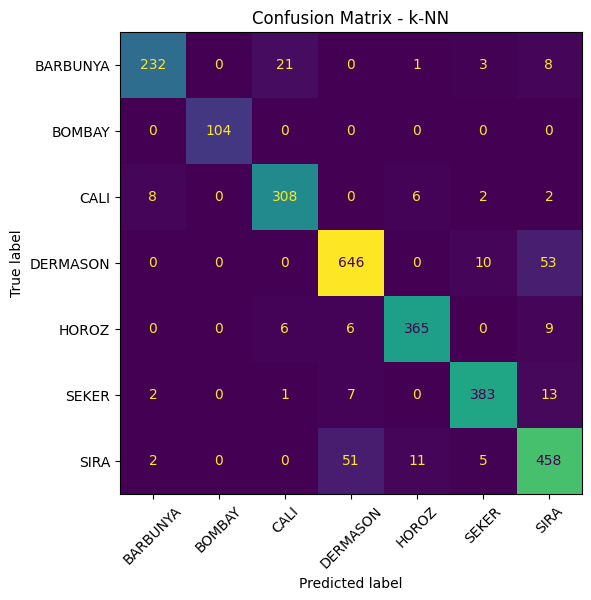

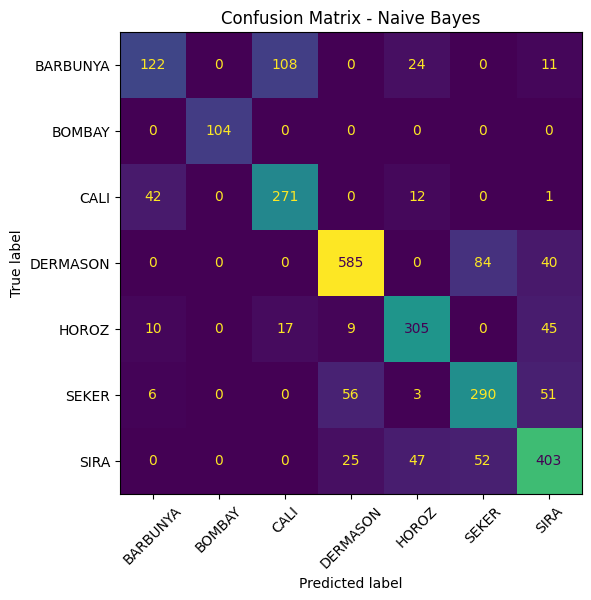

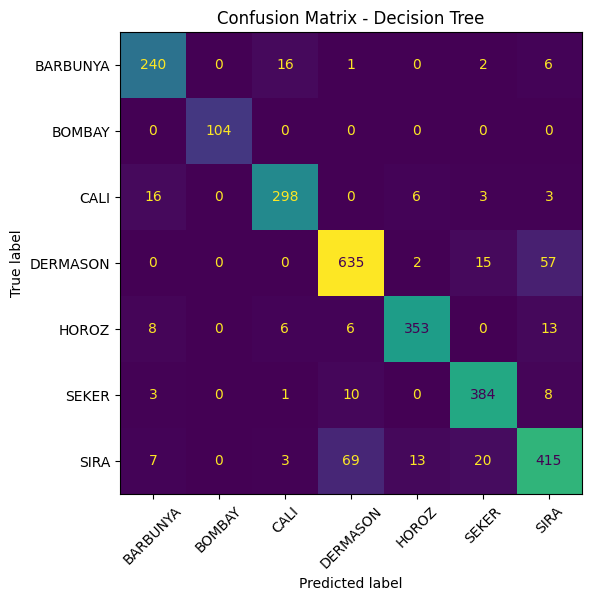

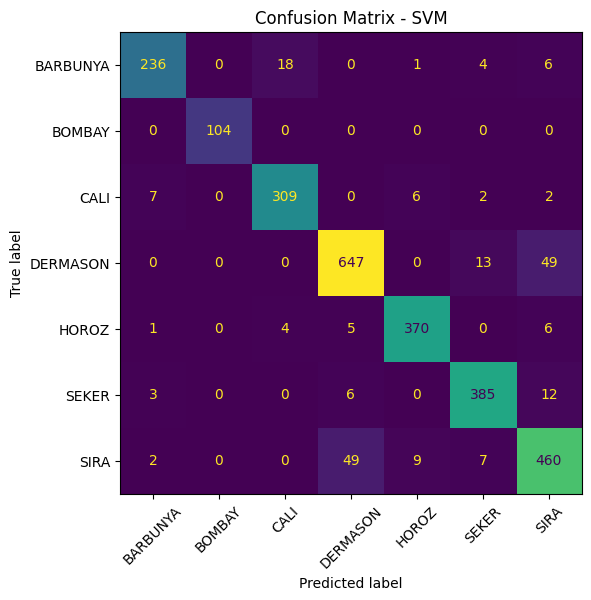

In [ ]:
for model_name, cm in conf_matrices.items():
    fig, ax = plt.subplots(figsize=(8, 6))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
    disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
    ax.set_title(f"Confusion Matrix - {model_name}")
    plt.show()

## 10. Best Model

The notebook selects the model with the highest **macro F1-score** from the evaluation results. In the saved run, **SVM** ranks first with **0.9221 accuracy** and **0.9343 macro F1-score** on the 2,723-record test set.

This ranking reflects one stratified train-test split; the notebook does not perform cross-validation or hyperparameter tuning.

In [ ]:
best_model_row = results_df.iloc[0]
print("Model terbaik berdasarkan F1-Score (Macro):")
display(best_model_row.to_frame(name="Value"))

best_model_name = best_model_row["Model"]
print(f"\nModel terbaik yang dipilih: {best_model_name}")

Model terbaik berdasarkan F1-Score (Macro):


,Value
Model,SVM
Accuracy,0.922145
Precision (Macro),0.935937
Recall (Macro),0.932952
F1-Score (Macro),0.934297



Model terbaik yang dipilih: SVM
